In [1]:
import pandas as pd
import matplotlib.pyplot as plt

crop_df = pd.read_csv("crop_yield.csv")
print(crop_df.shape)

(3000, 9)


In [2]:
crop_df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [3]:
crop_df.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [4]:
crop_df.dtypes

FARM_ID             object
CROP_TYPE           object
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE        object
DISTRICT            object
SEASON              object
FERTILIZER_USED     object
YIELD_VALUE          int64
dtype: object

In [5]:
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [6]:
crop_df.describe(exclude="number")

,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F3000,Wheat,19/03/2031,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [7]:
clean_df = crop_df.copy()
clean_df = clean_df.dropna(subset=["YIELD_KG"])
print("Rows before:", len(crop_df), " Rows after:", len(clean_df))

Rows before: 3000  Rows after: 2670


In [8]:
print("Missing before:", clean_df["AREA_ACRES"].isnull().sum())
clean_df["AREA_ACRES"] = clean_df["AREA_ACRES"].fillna(clean_df["AREA_ACRES"].mean())
print("Missing after:", clean_df["AREA_ACRES"].isnull().sum())

Missing before: 128
Missing after: 0


In [9]:
print("Missing before:", clean_df["DISTRICT"].isnull().sum())
clean_df["DISTRICT"] = clean_df["DISTRICT"].fillna("Unknown")
print("Missing after:", clean_df["DISTRICT"].isnull().sum())

Missing before: 109
Missing after: 0


In [10]:
print("Missing before:", clean_df["FERTILIZER_USED"].isnull().sum())
clean_df["FERTILIZER_USED"] = clean_df["FERTILIZER_USED"].fillna("No")
print("Missing after:", clean_df["FERTILIZER_USED"].isnull().sum())

Missing before: 283
Missing after: 0


In [11]:
print("Missing before:", clean_df["YIELD_VALUE"].isnull().sum())
clean_df["YIELD_VALUE"] = clean_df["YIELD_VALUE"].fillna(clean_df["YIELD_VALUE"].mean())
print("Missing after:", clean_df["YIELD_VALUE"].isnull().sum())

Missing before: 0
Missing after: 0


In [12]:
clean_df["HARVEST_DATE"] = pd.to_datetime(clean_df["HARVEST_DATE"], errors="coerce", format="%d/%m/%Y")
print("Invalid dates:", clean_df["HARVEST_DATE"].isnull().sum())
print("First date:", clean_df["HARVEST_DATE"].min(), " Last date:", clean_df["HARVEST_DATE"].max())

Invalid dates: 0
First date: 2023-01-01 00:00:00  Last date: 2031-03-19 00:00:00


In [13]:
clean_df["FARM_ID"] = clean_df["FARM_ID"].astype(str).str.replace("F", "").astype(int)
clean_df.head()

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,1,Wheat,1500.0,4.000000,2023-01-01,Sialkot,Rabi,Yes,30000
1,2,Wheat,1500.0,5.000000,2023-01-02,Multan,Rabi,No,30000
2,3,Wheat,2500.0,5.000000,2023-01-03,Faisalabad,Rabi,Yes,50000
3,4,Wheat,1500.0,4.412667,2023-01-04,Multan,Rabi,Yes,30000
4,5,Rice,1500.0,4.000000,2023-01-05,Faisalabad,Rabi,No,30000


In [14]:
clean_df.isnull().sum()

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

In [15]:
clean_df.dtypes

FARM_ID                     int64
CROP_TYPE                  object
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[ns]
DISTRICT                   object
SEASON                     object
FERTILIZER_USED            object
YIELD_VALUE                 int64
dtype: object

In [16]:
clean_df.to_csv("crop_yield_clean.csv", index=False)
print("Saved crop_yield_clean.csv with", len(clean_df), "rows")

Saved crop_yield_clean.csv with 2670 rows


In [17]:
crop_yield = clean_df.groupby("CROP_TYPE").agg({"YIELD_KG": "sum"})
crop_yield

,YIELD_KG
CROP_TYPE,
Maize,1112500.0
Rice,1638000.0
Sugarcane,592000.0
Wheat,2035500.0


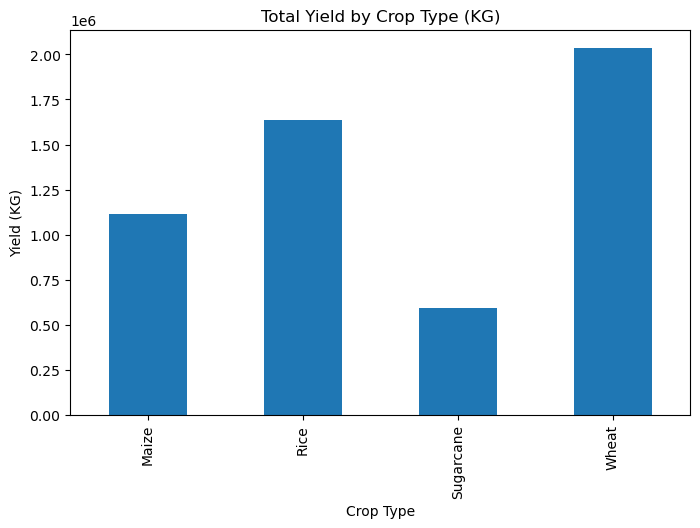

In [18]:
crop_yield.plot(kind="bar", legend=False, figsize=(8, 5))
plt.title("Total Yield by Crop Type (KG)")
plt.xlabel("Crop Type")
plt.ylabel("Yield (KG)")
plt.show()

In [19]:
yield_by_date = clean_df.pivot_table(values="YIELD_KG", index="HARVEST_DATE", aggfunc="sum")
yield_by_date.head(10)

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
2023-01-06,2000.0
2023-01-07,1500.0
2023-01-08,1500.0
2023-01-09,2000.0


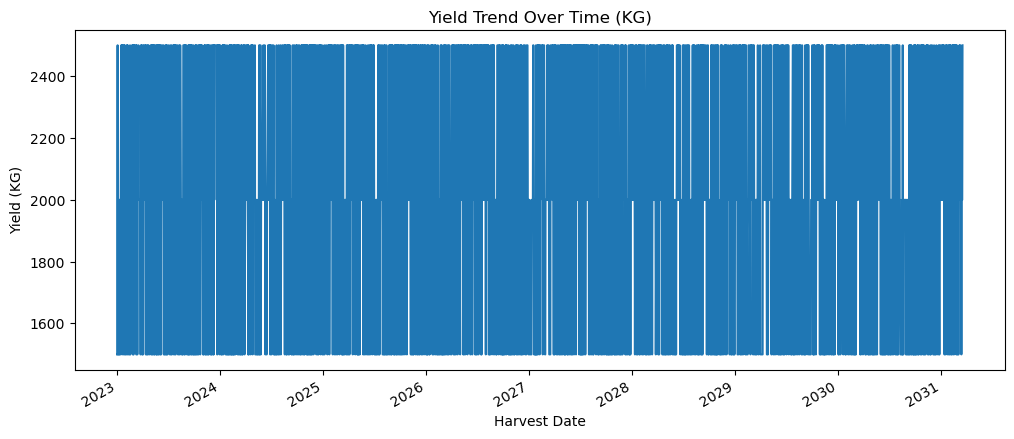

In [20]:
yield_by_date.plot(kind="line", legend=False, figsize=(12, 5))
plt.title("Yield Trend Over Time (KG)")
plt.xlabel("Harvest Date")
plt.ylabel("Yield (KG)")
plt.savefig("crop_yield_trend.png")
plt.show()